In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [3]:
from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix,
roc_curve,
auc)

In [4]:
data=load_breast_cancer()
x=data.data
y=data.target
print("Data Shape:",x.shape)
print("classes:",np.unique(y))

Data Shape: (569, 30)
classes: [0 1]


In [5]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)
mle_model=LogisticRegression(
    penalty=None,
    max_iter=5000,
    random_state=42
    )
mle_model.fit(x_train,y_train)
y_pred_mle=mle_model.predict(x_test)

In [7]:
map_l2=LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='lbfgs',
    max_iter=5000,
    random_state=42
)
map_l2.fit(x_train,y_train)
y_pred_l2=map_l2.predict(x_test)

In [8]:
map_l1=LogisticRegression(
    penalty='l1',
    C=1.0,
    solver='liblinear',
    max_iter=5000,
    random_state=42
)
map_l1.fit(x_train,y_train)
y_pred_l1=map_l1.predict(x_test)

In [9]:
def evaluate(model_name,y_true,y_pred):
    print("\n","="*40)
    print(model_name)
    print("="*40)
    print("Accuracy:",accuracy_score(y_true,y_pred))
    print("precision:",precision_score(y_true,y_pred))
    print("Recall:",recall_score(y_true,y_pred))
    print("F1 SCORE:",f1_score(y_true,y_pred))
    print("\nconfusion matrix:")
    print(confusion_matrix(y_true,y_pred))

In [10]:
evaluate("MLE",y_test,y_pred_mle)
evaluate("MAP(l2)",y_test,y_pred_l2)
evaluate("MAP(L1)",y_test,y_pred_l1)


MLE
Accuracy: 0.9210526315789473
precision: 0.9701492537313433
Recall: 0.9027777777777778
F1 SCORE: 0.935251798561151

confusion matrix:
[[40  2]
 [ 7 65]]

MAP(l2)
Accuracy: 0.9824561403508771
precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 SCORE: 0.9861111111111112

confusion matrix:
[[41  1]
 [ 1 71]]

MAP(L1)
Accuracy: 0.9912280701754386
precision: 0.9863013698630136
Recall: 1.0
F1 SCORE: 0.993103448275862

confusion matrix:
[[41  1]
 [ 0 72]]


In [11]:
print("number of zero coefficients")
print("MLE :",np.sum(mle_model.coef_[0]==0))
print("MAP L2 :",np.sum(map_l2.coef_[0]==0))
print("MAP L1 :",np.sum(map_l1.coef_[0]==0))

number of zero coefficients
MLE : 0
MAP L2 : 0
MAP L1 : 14


In [15]:
results=pd.DataFrame(columns=[
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
])
models=[
    ("MLE",mle_model,y_pred_mle),
     ("MAP L2",map_l2,y_pred_l2),
     ("MAP L1",map_l1,y_pred_l1)]

for name,model,pred in models:
    results.loc[len(results)]=[
        name,
        accuracy_score(y_test,pred),
        precision_score(y_test,pred),
        recall_score(y_test,pred),
        f1_score(y_test,pred)]
print(results)

    Model  Accuracy  Precision    Recall  F1 Score
0     MLE  0.921053   0.970149  0.902778  0.935252
1  MAP L2  0.982456   0.986111  0.986111  0.986111
2  MAP L1  0.991228   0.986301  1.000000  0.993103


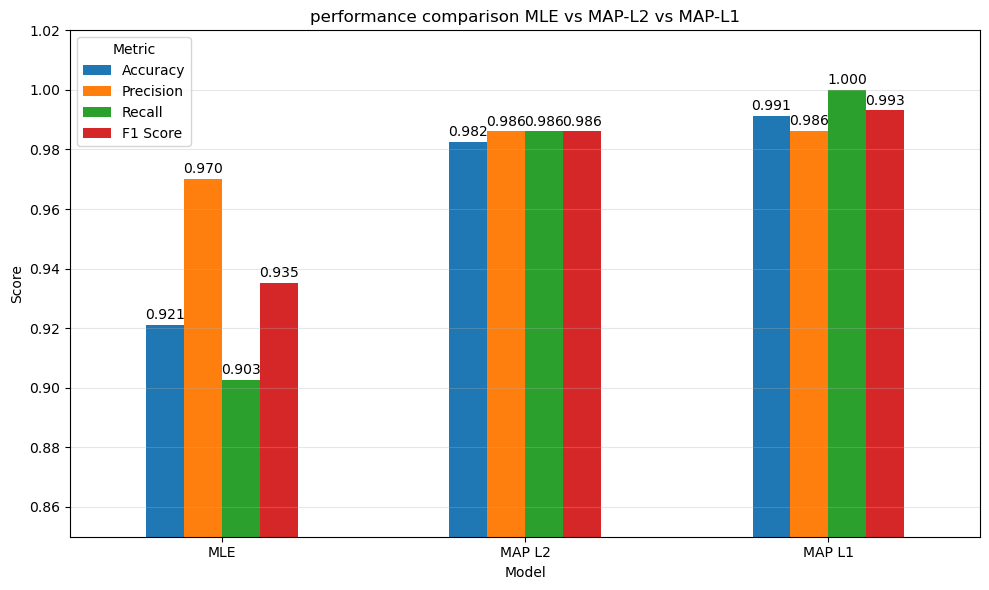

In [21]:
ax=results.set_index("Model").plot(
    kind="bar",
    figsize=(10,6)
)
plt.title("performance comparison MLE vs MAP-L2 vs MAP-L1")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0.85,1.02)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y",alpha=0.3)
for container in ax.containers:
    ax.bar_label(container,fmt="%.3f",padding=2)
plt.tight_layout()
plt.show()

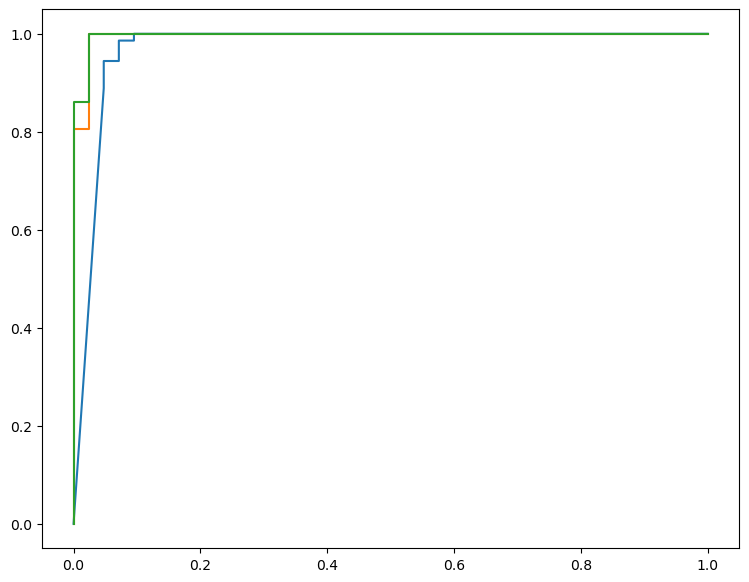

In [25]:
plt.figure(figsize=(9,7))
for name,model,pred in models:
    y_prob=model.predict_proba(x_test)[:,1]
    fpr,tpr,tresholds=roc_curve(y_test,y_prob)
    roc_auc=auc(fpr,tpr)
    plt.plot(
    fpr,
    tpr,
    label=f"{name}(AUC={roc_auc:.3f})")

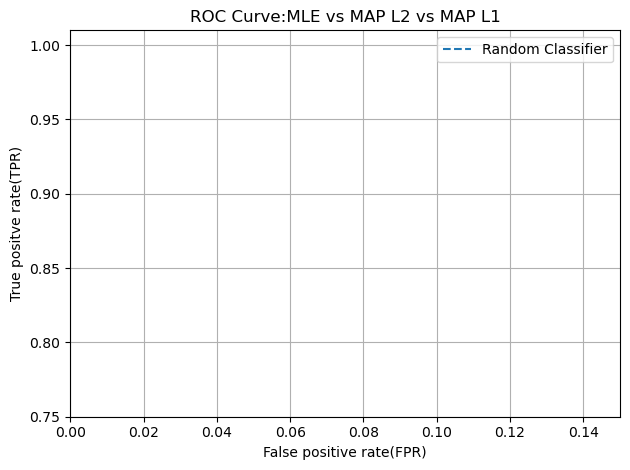

In [28]:
plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    label="Random Classifier")
plt.xlim(0,0.15)
plt.ylim(0.75,1.01)
plt.xlabel("False positive rate(FPR)")
plt.ylabel("True positve rate(TPR)")
plt.title("ROC Curve:MLE vs MAP L2 vs MAP L1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
    